# GCSI Headline Feed Live Polling

## Integration guide: Global Commodity Sentiment Indices, headline feed

The headline feed is the input to the hourly index: one row per headline × commodity × topic, each with a
**match type** and **three horizon scores**. Use it when you want your own aggregation windows, your own
filters, or the headlines behind a move. The same pattern, as three Docker services, is in
`app/live_headline_polling/`.

### Output schema

| Field | Description |
|---|---|
| `headline`, `link`, `source_name` | The article (publisher content: use it under your licence, do not republish) |
| `ticker` | The commodity |
| `match_type` | `EXPLICIT`, `RELATED_ENTITY` or `MACROECONOMIC` |
| `matched_entity_types`, `matched_entities` | What linked the headline to the commodity, e.g. `PHYSICAL_ASSET.PROCESSING_FACILITY` and `Ras Tanura Refinery`. Pipe-separated lists. |
| `country` | Countries the headline is about, pipe-separated |
| `source_country`, `language` | Where the publisher is based, and the language of the headline |
| `topic` | Topic label, `Sector::L1::L2` |
| `topic_probability` | Classifier confidence (0–1) that the headline belongs to the topic. This is not sentiment. |
| `short_term_sentiment_score` / `medium_term_…` / `long_term_…` | Horizon scores from −1 to +1, positive = bullish for price |
| `processed_at` | When Permutable received it (UTC). The hourly index is binned on this field. |

### What this notebook shows

1. Polling the feed into SQLite without duplicates
2. The match-type mix, and why `topic_probability` is a filter rather than a score
3. Who and where: the entities, countries and sources behind the news
4. Building your own 15-minute index, binned on **receipt time** so it matches the published hourly index

> **Disclaimer:** This notebook is provided for informational and research purposes only. Nothing here constitutes financial advice or a recommendation to buy, sell, or hold any asset. Sentiment scores are model outputs describing how news was judged at publication; they are not price forecasts.

In [ ]:
%pip install requests pandas numpy matplotlib seaborn

## Step 1: Configuration

In [2]:
import getpass
import hashlib
import os
import random
import sqlite3
import time
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch


def load_env_file() -> None:
    """Read KEY=VALUE pairs from the nearest .env file without overriding variables already set."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        env_path = base / '.env'
        if env_path.exists():
            for line in env_path.read_text().splitlines():
                line = line.strip()
                if line and not line.startswith('#') and '=' in line:
                    key, value = line.split('=', 1)
                    os.environ.setdefault(key.strip(), value.strip().strip('"'))
            return


def get_api_key() -> str:
    load_env_file()
    key = os.environ.get('API_KEY') or os.environ.get('PERMUTABLE_API_KEY')
    if not key:
        key = getpass.getpass('Enter your Permutable AI API key: ')
    return key


API_KEY = get_api_key()

TICKERS = ['BZ_COM']

# Display names for chart labels. Any ticker not listed is shown by its code.
TICKER_NAMES = {'BZ_COM': 'Brent Crude'}


def ticker_label(ticker: str) -> str:
    return TICKER_NAMES.get(ticker, ticker)


MATCH_TYPES = [None]               # None uses the API default COMBINED; or e.g. ['EXPLICIT', 'RELATED_ENTITY']
BACKFILL_HOURS = 48
POLL_INTERVAL_SECONDS = 900
MIN_TOPIC_PROBABILITY = 0.0        # raise to keep only confident topic assignments
AGG_FREQ = '15min'
DB_PATH = Path('gcsi_headlines_nb.db')

# Publisher text is shown when you run the notebook. The saved outputs in this repository were run with
# SHOW_HEADLINE_TEXT=0, so their tables leave out the headline, link and publisher.
SHOW_HEADLINE_TEXT = os.environ.get('SHOW_HEADLINE_TEXT', '1') == '1'
PUBLISHER_COLUMNS = ['headline', 'link', 'source_name']

HORIZONS = ['short_term_sentiment_score', 'medium_term_sentiment_score', 'long_term_sentiment_score']

BASE_URL = os.environ.get('BASE_URL', 'https://copilot-api.permutable.ai/v1')

# GCSI routes. The ticker and topic are query presets, not part of the path.
FEED_LIVE_PATH = '/headlines/feed/live/gcsi'
FEED_HISTORICAL_PATH = '/headlines/feed/historical/gcsi'
PAGE_LIMIT = 1000
MAX_LOOKBACK_DAYS = 90

## Step 2: Fetch and storage helpers

The feed has no row id, so each row gets a key built from (ticker, topic, match type, link or headline,
publication time). Polling the same window twice is then harmless.

In [3]:
SESSION = requests.Session()
SESSION.headers.update({'x-api-key': API_KEY, 'accept': 'application/json'})


def api_get(path: str, params: dict | None = None, max_retries: int = 5):
    """GET a Permutable API path, backing off exponentially (with jitter) on 429 and 5xx responses."""
    params = {k: v for k, v in (params or {}).items() if v is not None}
    delay = 1.0
    for attempt in range(max_retries + 1):
        response = SESSION.get(BASE_URL + path, params=params, timeout=60)
        if response.status_code == 429 or response.status_code >= 500:
            if attempt == max_retries:
                response.raise_for_status()
            time.sleep(delay + random.uniform(0, delay / 2))
            delay *= 2
            continue
        if response.status_code in (401, 403):
            raise PermissionError(
                f'{response.status_code} on {path}: check the API key, and that your licence includes GCSI.'
            )
        response.raise_for_status()
        return response.json()


def _records(body) -> list[dict]:
    """Live endpoints return a list; historical endpoints return {data, has_more, next_token}."""
    return body['data'] if isinstance(body, dict) else body


def _stamp(records: list[dict], **dims) -> list[dict]:
    """Responses can omit the dimensions you asked for, so write them back onto each record."""
    for record in records:
        for key, value in dims.items():
            if value is not None:
                record.setdefault(key, value)
    return records


def _paginate(path: str, params: dict) -> list[dict]:
    params = {**params, 'limit': PAGE_LIMIT}
    rows: list[dict] = []
    while True:
        body = api_get(path, params)
        rows.extend(_records(body))
        if not (isinstance(body, dict) and body.get('has_more')):
            return rows
        params['next_token'] = body['next_token']


TOPIC_SEPARATOR = '::'  # Sector::L1::L2, the form the API returns


def normalise_topic(labels: pd.Series) -> pd.Series:
    """Write each label as sector, driver and topic joined by TOPIC_SEPARATOR, whatever separator the source used."""
    return labels.astype('string').str.replace(r'\s*(?:::|-)\s*', TOPIC_SEPARATOR, regex=True)


def fetch_live_feed(ticker: str, match_type: str | None = None) -> list[dict]:
    params = {'ticker_preset': ticker, 'match_type': match_type, 'limit': PAGE_LIMIT}
    return _stamp(_records(api_get(FEED_LIVE_PATH, params)), ticker=ticker)


def fetch_historical_feed(ticker: str, start: datetime, end: datetime | None = None, match_type: str | None = None) -> list[dict]:
    params = {'ticker_preset': ticker, 'match_type': match_type, 'start_date': start.date().isoformat(),
              'end_date': end.date().isoformat() if end else None, 'limit': PAGE_LIMIT}
    return _stamp(_paginate(FEED_HISTORICAL_PATH, params), ticker=ticker)


FEED_COLUMNS = ['row_key', 'ticker', 'match_type', 'topic', 'topic_probability', *HORIZONS,
                'matched_entity_types', 'matched_entities', 'country', 'source_country', 'language',
                'headline', 'link', 'source_name', 'processed_at', 'fetched_at']


def row_key(record: dict) -> str:
    parts = [record.get(k) or '' for k in ('ticker', 'topic', 'match_type', 'processed_at')]
    parts.append(record.get('link') or record.get('headline') or '')
    return hashlib.sha1('|'.join(map(str, parts)).encode()).hexdigest()


def setup_database(db_path: Path = DB_PATH) -> None:
    columns = ', '.join(f'{c} TEXT' if c not in ('topic_probability', *HORIZONS) else f'{c} REAL' for c in FEED_COLUMNS)
    with sqlite3.connect(db_path) as conn:
        conn.execute(f'CREATE TABLE IF NOT EXISTS gcsi_headlines ({columns}, PRIMARY KEY (row_key))')


def upsert_feed(records: list[dict], db_path: Path = DB_PATH) -> int:
    if not records:
        return 0
    fetched_at = datetime.now(timezone.utc).isoformat()
    rows = [tuple(row_key(r) if c == 'row_key' else fetched_at if c == 'fetched_at' else r.get(c) for c in FEED_COLUMNS)
            for r in records]
    with sqlite3.connect(db_path) as conn:
        conn.executemany(
            f'INSERT OR REPLACE INTO gcsi_headlines ({", ".join(FEED_COLUMNS)}) VALUES ({", ".join("?" * len(FEED_COLUMNS))})',
            rows,
        )
    return len(rows)


def load_feed(hours: int = BACKFILL_HOURS) -> pd.DataFrame:
    with sqlite3.connect(DB_PATH) as conn:
        frame = pd.read_sql('SELECT * FROM gcsi_headlines', conn)
    frame['processed_at'] = pd.to_datetime(frame['processed_at'], utc=True, format='ISO8601')
    frame['topic'] = normalise_topic(frame['topic'])
    since = pd.Timestamp.now(tz='UTC') - pd.Timedelta(hours=hours)
    return frame[frame['processed_at'] >= since].reset_index(drop=True)


setup_database()
print('Database ready:', DB_PATH)

Database ready: gcsi_headlines_nb.db


## Step 3: Dry run and backfill

In [4]:
sample = fetch_live_feed(TICKERS[0])
print(f'{len(sample)} live rows for {TICKERS[0]}; fields: {sorted(sample[0]) if sample else "none"}')

start = datetime.now(timezone.utc) - timedelta(hours=BACKFILL_HOURS)
for ticker in TICKERS:
    for match_type in MATCH_TYPES:
        n = upsert_feed(fetch_historical_feed(ticker, start, match_type=match_type))
        print(f'{ticker} / {match_type or "all match types"}: {n:,} rows upserted')

feed = load_feed()
feed = feed[feed['topic_probability'] >= MIN_TOPIC_PROBABILITY]
print(f'{len(feed):,} rows | {feed["link"].nunique():,} distinct links | {feed["topic"].nunique()} topics')

1000 live rows for BZ_COM; fields: ['country', 'headline', 'language', 'link', 'long_term_sentiment_score', 'match_type', 'matched_entities', 'matched_entity_types', 'medium_term_sentiment_score', 'processed_at', 'short_term_sentiment_score', 'source_country', 'source_name', 'ticker', 'topic', 'topic_probability']


BZ_COM / all match types: 25,508 rows upserted
24,333 rows | 20,122 distinct links | 21 topics


## Step 4: Match types and topic probability

One headline can appear several times for a ticker: once per topic. Within a ticker, each headline has a single
match type (priority `EXPLICIT`, then `RELATED_ENTITY`, then `MACROECONOMIC`).
`topic_probability` measures how sure the classifier is about the *topic*. A low value does not mean low
sentiment, so use it to trade coverage for precision.

,rows,links,avg_short_term
match_type,,,
EXPLICIT,10327,7539,-0.247
MACROECONOMIC,13042,11748,0.010
RELATED_ENTITY,964,835,-0.048


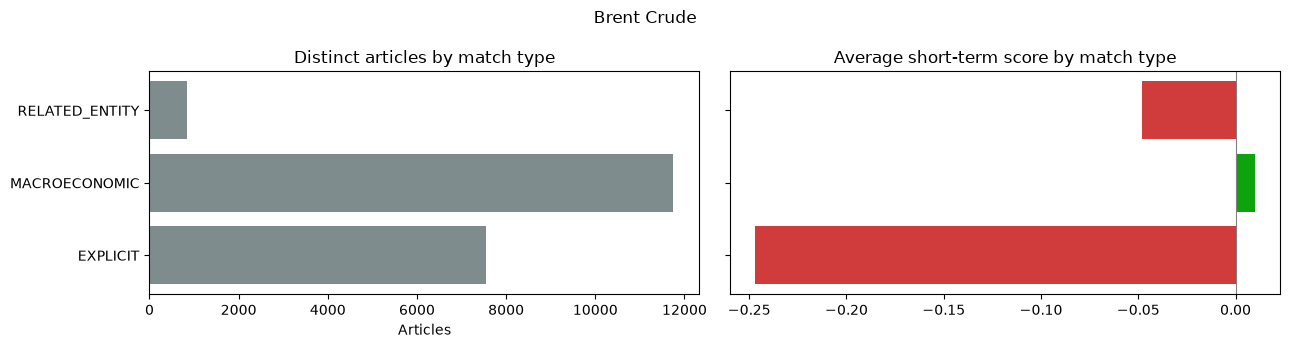

In [5]:
mix = feed.groupby('match_type').agg(rows=('row_key', 'size'), links=('link', 'nunique'),
                                      avg_short_term=('short_term_sentiment_score', 'mean')).round(3)
display(mix)

fig, (ax_rows, ax_avg) = plt.subplots(1, 2, figsize=(13, 3.5))
ax_rows.barh(mix.index, mix['links'], color='#7f8c8d')
ax_rows.set_title('Distinct articles by match type')
ax_rows.set_xlabel('Articles')
ax_avg.barh(mix.index, mix['avg_short_term'], color=['#d03b3b' if v < 0 else '#0ca30c' for v in mix['avg_short_term']])
ax_avg.axvline(0, color='grey', lw=0.8)
ax_avg.set_title('Average short-term score by match type')
ax_avg.set_yticklabels([])
plt.suptitle(ticker_label(TICKERS[0]))
plt.tight_layout()
plt.show()

## Step 5: Who and where: entities, countries and coverage

Each headline also records **what** linked it to the commodity (`matched_entity_types`, `matched_entities`),
**which countries** it is about (`country`) and **where it came from** (`source_country`, `language`).
The first three are `|`-separated lists, so split them and count each article once per value.

Counts are distinct articles. The feed repeats an article once per topic, so each article's short-term score is
averaged across its topics before it is averaged by entity or country.

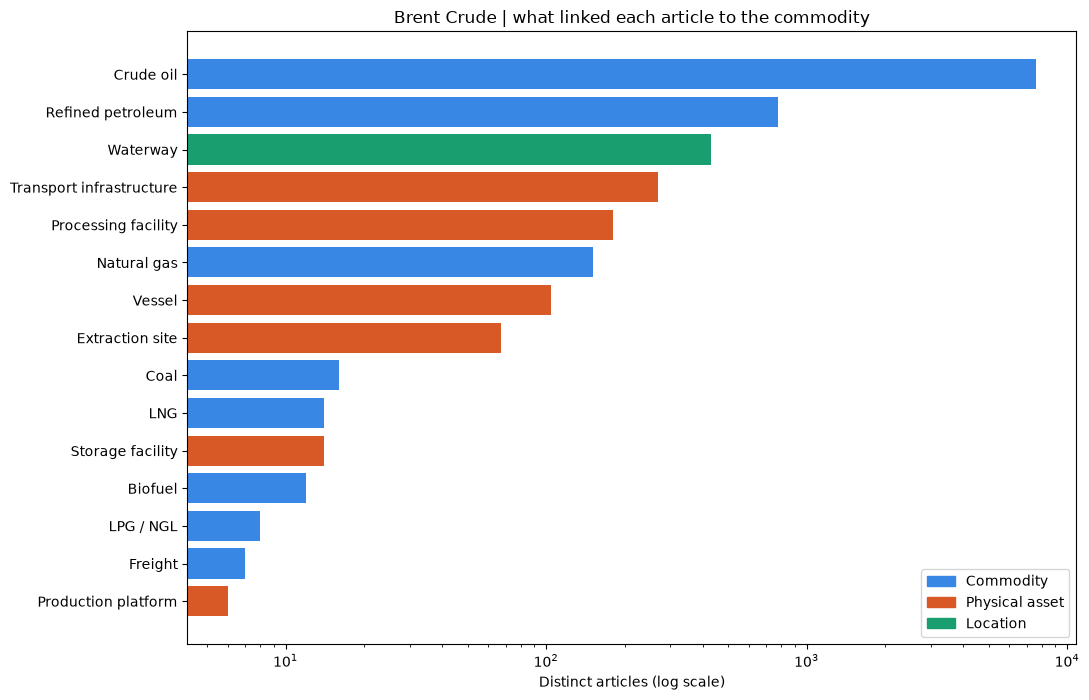

In [6]:
LIST_SEPARATOR = '|'
FAMILY_COLOURS = {'COMMODITY': '#3987e5', 'PHYSICAL_ASSET': '#d95926', 'LOCATION': '#199e70',
                  'POLICY_INSTRUMENT': '#c98500'}
LANGUAGES = {'en': 'English', 'ar': 'Arabic', 'zh': 'Chinese', 'es': 'Spanish', 'pt': 'Portuguese', 'ru': 'Russian',
             'de': 'German', 'fr': 'French', 'ja': 'Japanese', 'ko': 'Korean', 'it': 'Italian', 'tr': 'Turkish',
             'bg': 'Bulgarian', 'ro': 'Romanian', 'pl': 'Polish', 'uk': 'Ukrainian', 'hi': 'Hindi', 'id': 'Indonesian',
             'fa': 'Persian', 'el': 'Greek', 'nl': 'Dutch', 'vi': 'Vietnamese', 'he': 'Hebrew', 'th': 'Thai'}
TYPE_LABELS = {'LNG': 'LNG', 'LPG_NGL': 'LPG / NGL', 'FERROUS_METAL_STEEL': 'Ferrous metal / steel'}


def articles(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per article, with its short-term score averaged across the topics it appears under."""
    fields = ['matched_entity_types', 'matched_entities', 'country', 'source_country', 'language']
    return frame.groupby('link', as_index=False).agg(
        **{field: (field, 'first') for field in fields}, score=('short_term_sentiment_score', 'mean')
    )


def explode_list(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    """One row per article and value of a `|`-separated column."""
    out = frame.assign(**{column: frame[column].str.split(LIST_SEPARATOR)}).explode(column)
    out[column] = out[column].str.strip()
    return out[out[column].fillna('') != ''].drop_duplicates(['link', column])


def by_value(frame: pd.DataFrame, column: str, n: int = 12) -> pd.DataFrame:
    """Distinct articles and average short-term score for the n most frequent values, smallest first for barh."""
    out = frame.groupby(column).agg(articles=('link', 'nunique'), avg_short_term=('score', 'mean'))
    return out.nlargest(n, 'articles').sort_values('articles')


news = articles(feed)

# Entity types are FAMILY.TYPE, e.g. PHYSICAL_ASSET.PROCESSING_FACILITY
types = by_value(explode_list(news, 'matched_entity_types'), 'matched_entity_types', n=15)
families = types.index.str.split('.').str[0]
names = [TYPE_LABELS.get(t, t.replace('_', ' ').capitalize()) for t in types.index.str.split('.').str[-1]]
fig, ax = plt.subplots(figsize=(11, 0.38 * len(types) + 1.4))
ax.barh(names, types['articles'], color=[FAMILY_COLOURS.get(f, '#7f8c8d') for f in families])
ax.legend(handles=[Patch(color=colour, label=family.replace('_', ' ').capitalize())
                   for family, colour in FAMILY_COLOURS.items() if family in set(families)], loc='lower right')
ax.set_title(f'{ticker_label(TICKERS[0])} | what linked each article to the commodity')
ax.set_xscale('log')   # the commodity itself usually dwarfs the rest
ax.set_xlabel('Distinct articles (log scale)')
plt.tight_layout()
plt.show()

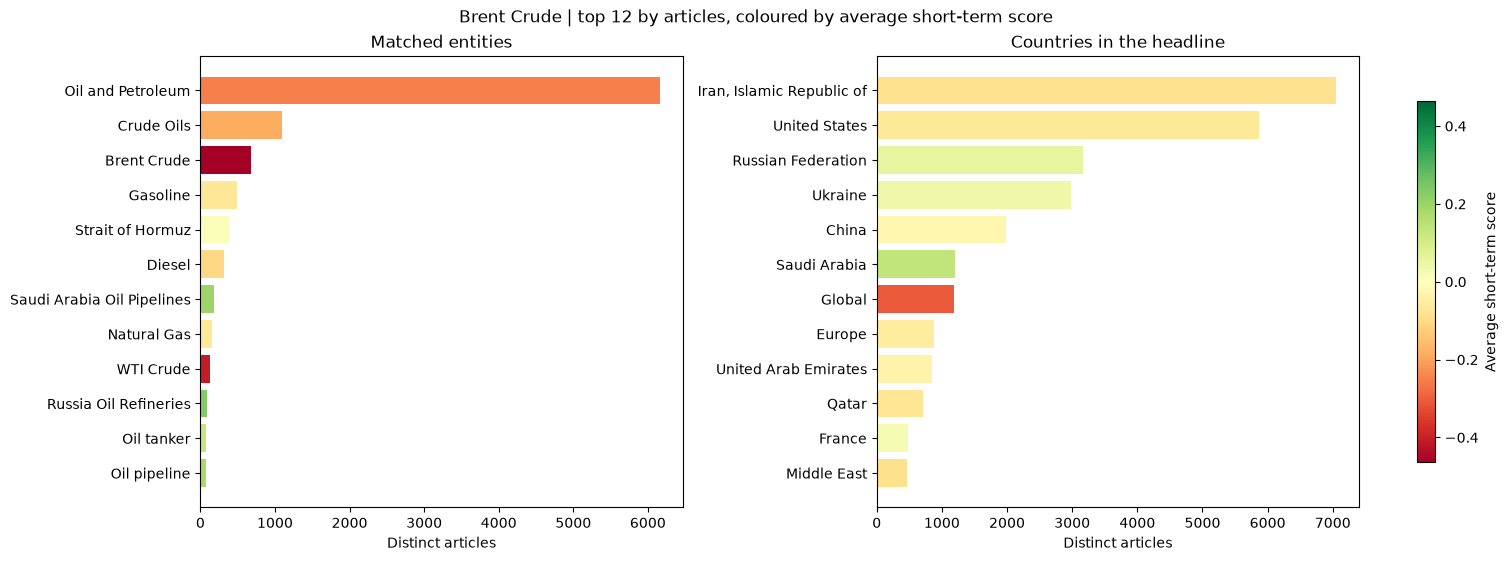

In [7]:
entities = by_value(explode_list(news, 'matched_entities'), 'matched_entities')
countries = by_value(explode_list(news, 'country'), 'country')

limit = max(entities['avg_short_term'].abs().max(), countries['avg_short_term'].abs().max(), 0.05)
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
cmap = plt.get_cmap('RdYlGn')
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), layout='constrained')
for ax, table, title in [(axes[0], entities, 'Matched entities'), (axes[1], countries, 'Countries in the headline')]:
    ax.barh(table.index, table['articles'], color=cmap(norm(table['avg_short_term'])))
    ax.set_title(title)
    ax.set_xlabel('Distinct articles')
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=0.8, label='Average short-term score')
fig.suptitle(f'{ticker_label(TICKERS[0])} | top 12 by articles, coloured by average short-term score')
plt.show()

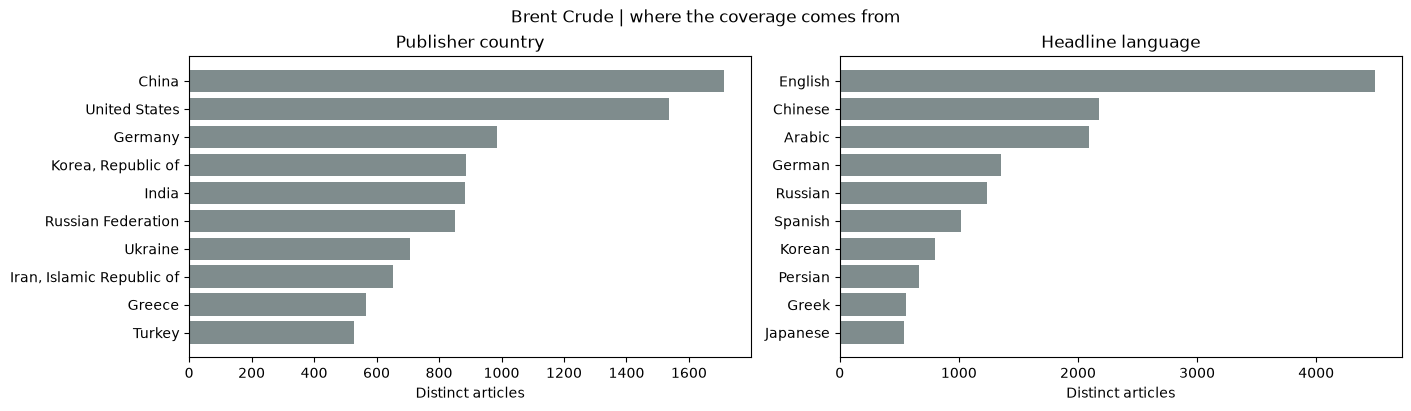

In [8]:
sources = news.groupby('source_country')['link'].nunique().nlargest(10).sort_values()
languages = news.groupby('language')['link'].nunique().nlargest(10).sort_values()
languages.index = [LANGUAGES.get(code, code) for code in languages.index]

fig, (ax_src, ax_lang) = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
ax_src.barh(sources.index, sources.values, color='#7f8c8d')
ax_src.set_title('Publisher country')
ax_lang.barh(languages.index, languages.values, color='#7f8c8d')
ax_lang.set_title('Headline language')
for ax in (ax_src, ax_lang):
    ax.set_xlabel('Distinct articles')
fig.suptitle(f'{ticker_label(TICKERS[0])} | where the coverage comes from')
plt.show()

## Step 6: Your own index on receipt time

Bin on `processed_at` (when Permutable received the headline), labelling each bin by its **end**, as the
hourly index does. The feed does not carry a publisher publication time.

One article can appear in several topics, so the `headline_count` here counts topic-links.

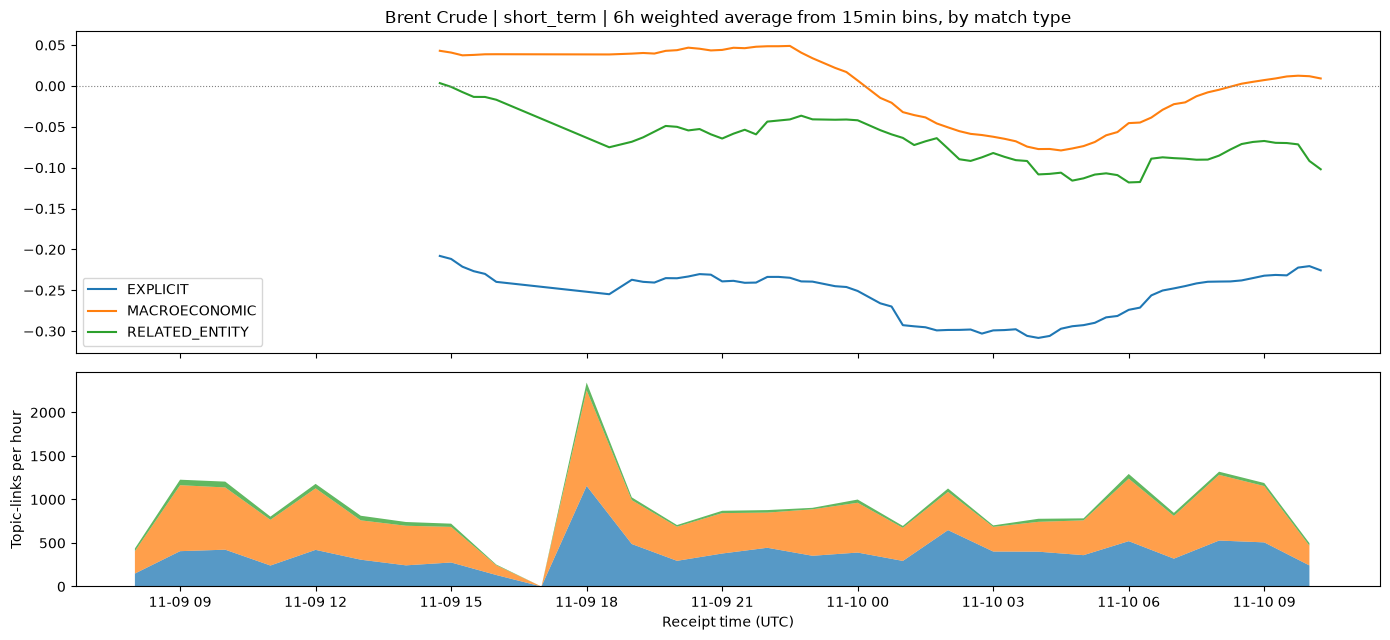

In [9]:
def own_index(frame: pd.DataFrame, horizon: str = 'short_term_sentiment_score', freq: str = AGG_FREQ) -> pd.DataFrame:
    binned = frame.assign(bin_end=frame['processed_at'].dt.floor(freq) + pd.Timedelta(freq))
    out = binned.groupby(['ticker', 'match_type', 'bin_end']).agg(
        headline_count=(horizon, 'size'),
        sentiment_sum=(horizon, 'sum'),
        sentiment_std=(horizon, 'std'),
    ).reset_index()
    out['sentiment_std'] = out['sentiment_std'].fillna(0.0)   # matches the index: 0 for a single headline
    out['sentiment_avg'] = out['sentiment_sum'] / out['headline_count']
    return out


own = own_index(feed)
fig, (ax, ax_vol) = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
for match_type, group in own.groupby('match_type'):
    rolled = group.set_index('bin_end')[['sentiment_sum', 'headline_count']].rolling('6h').sum()
    rolled = rolled[rolled.index >= rolled.index.min() + pd.Timedelta('6h')]   # drop the warm-up window
    ax.plot(rolled.index, rolled['sentiment_sum'] / rolled['headline_count'], label=match_type)
ax.axhline(0, color='grey', lw=0.8, ls=':')
ax.set_title(f'{ticker_label(TICKERS[0])} | short_term | 6h weighted average from {AGG_FREQ} bins, by match type')
ax.legend()
volume = own.pivot_table(index='bin_end', columns='match_type', values='headline_count', aggfunc='sum').fillna(0)
hourly_volume = volume.resample('1h').sum()
ax_vol.stackplot(hourly_volume.index, hourly_volume.T.to_numpy(), labels=hourly_volume.columns, alpha=0.75)
ax_vol.set_ylabel('Topic-links per hour')
ax_vol.set_xlabel('Receipt time (UTC)')
plt.tight_layout()
plt.show()

## Step 7: Topic heatmap

The busiest topics in the window, with cells under five topic-links left blank.

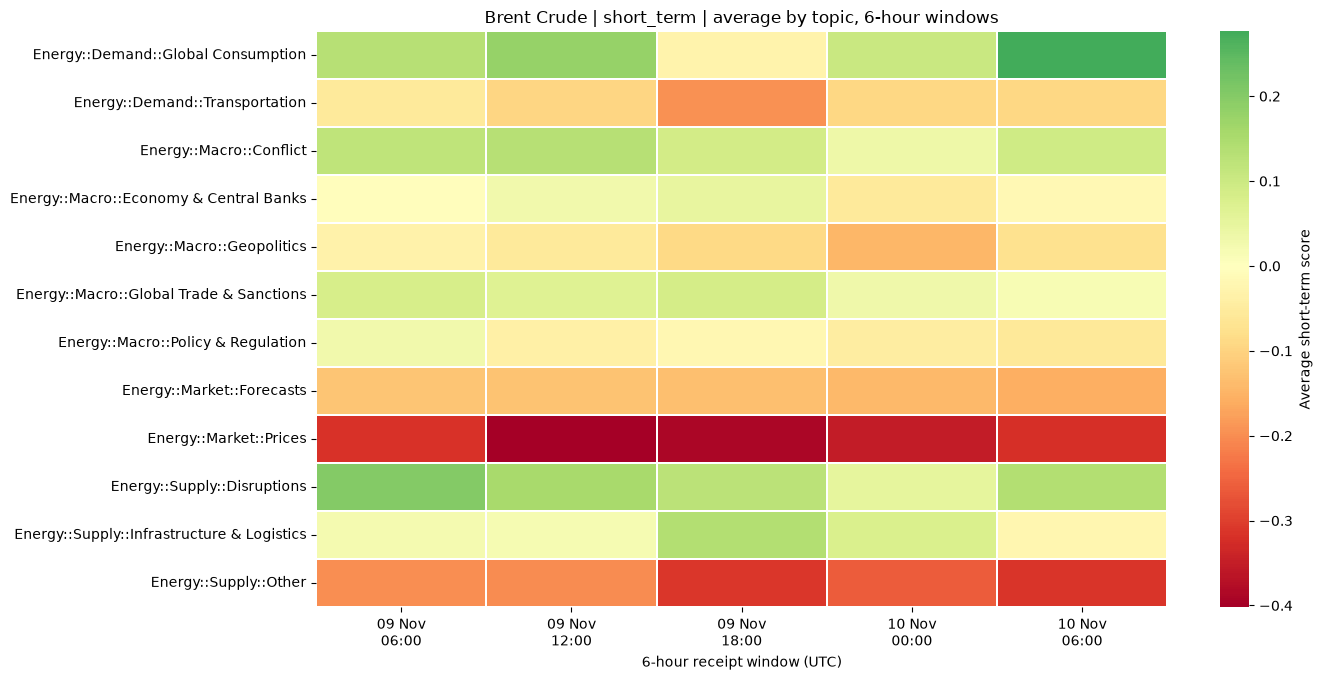

In [10]:
top = feed['topic'].value_counts().head(12).index
sub = feed[feed['topic'].isin(top)].assign(hour=lambda f: f['processed_at'].dt.floor('6h'))
grid = sub.groupby(['topic', 'hour'])['short_term_sentiment_score'].agg(['mean', 'size'])
heat = grid['mean'].where(grid['size'] >= 5).unstack()
heat.columns = heat.columns.strftime('%d %b\n%H:00')
fig, ax = plt.subplots(figsize=(14, 0.45 * len(heat) + 1.5))
sns.heatmap(heat, cmap='RdYlGn', center=0, linewidths=0.3, ax=ax, cbar_kws={'label': 'Average short-term score'})
ax.set_title(f'{ticker_label(TICKERS[0])} | short_term | average by topic, 6-hour windows')
ax.set_xlabel('6-hour receipt window (UTC)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## Step 8: Strongest headlines

The headlines behind the most recent move, ranked by absolute short-term score. These are for your own analysis.
Publisher text should not be republished: set `SHOW_HEADLINE_TEXT` to see it, as the saved outputs here do not.

In [11]:
recent = feed[feed['processed_at'] >= feed['processed_at'].max() - pd.Timedelta(hours=6)]
strongest = recent.reindex(recent['short_term_sentiment_score'].abs().sort_values(ascending=False).index)
columns = ['processed_at', 'match_type', 'topic', 'short_term_sentiment_score', 'country', 'matched_entities',
           'headline', 'source_name']
if not SHOW_HEADLINE_TEXT:
    columns = [c for c in columns if c not in PUBLISHER_COLUMNS]
display(strongest.drop_duplicates('link')[columns].head(10))

,processed_at,match_type,topic,short_term_sentiment_score,country,matched_entities
21037,2026-11-10 07:24:21.450182+00:00,EXPLICIT,Energy::Market::Prices,-0.995,India,Crude Oils
18767,2026-11-10 05:09:04.663598+00:00,EXPLICIT,Energy::Market::Prices,-0.995,Global,Oil and Petroleum
20919,2026-11-10 07:17:00.875990+00:00,EXPLICIT,Energy::Market::Prices,-0.995,United States,Crude Oils
18799,2026-11-10 05:09:04.663598+00:00,EXPLICIT,Energy::Market::Prices,-0.993,India,Crude Oils
18795,2026-11-10 05:09:04.663598+00:00,EXPLICIT,Energy::Market::Prices,-0.993,India,Crude Oils
24222,2026-11-10 10:02:25.273803+00:00,EXPLICIT,Energy::Market::Prices,-0.991,"Iran, Islamic Republic of",Brent Crude|Crude Oils
23145,2026-11-10 09:15:37.295891+00:00,EXPLICIT,Energy::Market::Prices,-0.984,"Iran, Islamic Republic of|Saudi Arabia",Brent Crude|Crude Oils|Oil and Petroleum
18028,2026-11-10 04:15:51.414498+00:00,EXPLICIT,Energy::Market::Prices,-0.983,"Global|Iran, Islamic Republic of|Qatar|Saudi A...",Oil and Petroleum
18338,2026-11-10 04:41:17.909516+00:00,EXPLICIT,Energy::Market::Prices,-0.982,China,Oil and Petroleum
18774,2026-11-10 05:09:04.663598+00:00,EXPLICIT,Energy::Market::Prices,0.982,France,Oil and Petroleum


## Step 9: Live polling loop

In [12]:
RUN_POLLING_LOOP = False

if RUN_POLLING_LOOP:
    while True:
        started = datetime.now(timezone.utc)
        n = sum(upsert_feed(fetch_live_feed(t, m)) for t in TICKERS for m in MATCH_TYPES)
        print(f'{started:%H:%M:%S} UTC: {n} rows upserted')
        time.sleep(max(0, POLL_INTERVAL_SECONDS - (datetime.now(timezone.utc) - started).total_seconds()))
else:
    print('Polling loop disabled: set RUN_POLLING_LOOP = True to start it.')

Polling loop disabled: set RUN_POLLING_LOOP = True to start it.
